# 4.0 PCA Diagnóstico (Muestra 10,000 filas)

**CRISP-DM Fase 3 · *Data Preparation* · Diagnóstico de Componentes Principales (PCA).**
Cuaderno satélite de `3.0_transformacion.ipynb`: analiza la estructura espectral (varianza explicada y *loadings*) de las 11 variables numéricas escaladas sobre el nuevo universo clasificado (`1,738,738` experiencias laborales, `352,093` personas), comparando **Versión A (`con_outliers`)** frente a **Versión B (`sin_outliers`)**.
Muestra aleatoria reproducible (`seed = 42`): `min(10,000, n)` filas por versión.

In [1]:
# Cell 1: All library and module imports, relative paths, and fixed seed
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
if ROOT.name == "refactor":
    ROOT = ROOT.parent.parent
elif ROOT.name == "notebooks":
    ROOT = ROOT.parent
elif ROOT.name != "MineriaProtect":
    for p in [ROOT] + list(ROOT.parents):
        if p.name == "MineriaProtect":
            ROOT = p
            break
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts.ScriptsCsv.Transformacion.column_profile import profile_columns
from scripts.ScriptsCsv.Transformacion.config import VERSION_CON, VERSION_SIN, processed_path
from scripts.ScriptsCsv.Transformacion.date_features import add_date_ordinals, add_job_order, add_start_year
from scripts.ScriptsCsv.Transformacion.encoding import derive_skill_presence, ordinal_from_mapping
from scripts.ScriptsCsv.Transformacion.pca_diagnostic import components_for_threshold, run_pca, top_loadings
from scripts.ScriptsCsv.Transformacion.scaling import fit_transform_full

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
SAMPLE_SIZE = 10000
print(f"Configuración PCA lista | Muestra = {SAMPLE_SIZE} filas | Semilla = {RANDOM_SEED}")

Configuración PCA lista | Muestra = 10000 filas | Semilla = 42


In [2]:
# Cell 2: Read both versions in RAM and filter to classified ESCO universe
UNIV_ORDER = {"No reportado": 0, "Secondary school": 1, "Bachelor": 2, "Master": 3, "PhD": 4}
SCALING_PLAN = {
    "start_ord": "robust", "end_ord": "robust", "dur_q": "robust",
    "n_skills_essential": "robust", "n_skills_competence": "robust",
    "n_skills_knowledge": "robust", "n_skills_sin_tipo": "robust",
    "veces_ese_oficio": "robust", "start_year": "robust",
    "job_order": "robust", "univ_ord": "minmax",
}
def read_version(version):
    path = processed_path(version)
    df = pd.read_csv(path, dtype=str, encoding="utf-8", keep_default_na=False, na_values=[""])
    occupation = df["occupation_code"].fillna("").astype(str).str.strip()
    fusion = occupation.eq("") & df["matched_code"].astype(str).str.strip().ne("unknown")
    occupation.loc[fusion] = df.loc[fusion, "matched_code"].astype(str)
    df["occupation_code"] = occupation.replace("", pd.NA).fillna("unknown")
    df = add_date_ordinals(df, "start_date", "end_date")
    df = add_start_year(df)
    df = add_job_order(df, "resume_id", "start_ord")
    for col in ["n_skills_essential", "n_skills_competence", "n_skills_knowledge", "n_skills_sin_tipo", "veces_ese_oficio"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    df = derive_skill_presence(df, ["skills", "knowledge", "sin_tipo"], ["tiene_skills", "tiene_knowledge", "tiene_sin_tipo"])
    df = ordinal_from_mapping(df, "university_level", UNIV_ORDER, "univ_ord")
    return df

df_con = read_version(VERSION_CON)
df_sin = read_version(VERSION_SIN)
work_con = df_con[df_con.n_skills_essential.notna()].copy().reset_index(drop=True)
work_sin = df_sin[df_sin.n_skills_essential.notna()].copy().reset_index(drop=True)
print("Universo con/sin:", work_con.shape, work_sin.shape)

Universo con/sin: (1738738, 32) (1738738, 32)


In [3]:
sample_n = lambda n, size: min(size, len(n))
sample_con = work_con[sorted(set(SCALING_PLAN))].sample(n=sample_n(work_con, SAMPLE_SIZE), random_state=RANDOM_SEED)
sample_sin = work_sin[sorted(set(SCALING_PLAN))].sample(n=sample_n(work_sin, SAMPLE_SIZE), random_state=RANDOM_SEED)
_, scaled_con = fit_transform_full(sample_con, SCALING_PLAN)
_, scaled_sin = fit_transform_full(sample_sin, SCALING_PLAN)

var_con, load_con, _ = run_pca(scaled_con, n_components=10)
var_sin, load_sin, _ = run_pca(scaled_sin, n_components=10)
print("Componentes 80/90 (con):", components_for_threshold(var_con, 0.80), components_for_threshold(var_con, 0.90))
print("Componentes 80/90 (sin):", components_for_threshold(var_sin, 0.80), components_for_threshold(var_sin, 0.90))
display(var_con)
display(var_sin)


Componentes 80/90 (con): 4 5
Componentes 80/90 (sin): 3 5


,component,explained_variance_ratio,cumulative_variance
0,PC1,0.329837,0.329837
1,PC2,0.228199,0.558037
2,PC3,0.214099,0.772136
3,PC4,0.106173,0.878309
4,PC5,0.062208,0.940517
5,PC6,0.053769,0.994286
6,PC7,0.004599,0.998884
7,PC8,0.001071,0.999955
8,PC9,0.000045,1.000000
9,PC10,0.000000,1.000000


,component,explained_variance_ratio,cumulative_variance
0,PC1,0.396655,0.396655
1,PC2,0.259909,0.656564
2,PC3,0.150967,0.807531
3,PC4,0.083712,0.891243
4,PC5,0.062496,0.953739
5,PC6,0.039102,0.992840
6,PC7,0.005498,0.998338
7,PC8,0.001289,0.999628
8,PC9,0.000318,0.999946
9,PC10,0.000054,1.000000



Top loadings PC1 (con):


,abs_loading,signed_loading
dur_q_rob,0.832491,0.832491
start_ord_rob,0.353979,-0.353979
start_year_rob,0.350190,-0.350190
job_order_rob,0.170987,-0.170987
end_ord_rob,0.112057,-0.112057
veces_ese_oficio_rob,0.075023,-0.075023



Top loadings PC1 (sin):


,abs_loading,signed_loading
dur_q_rob,0.840422,0.840422
start_ord_rob,0.355151,-0.355151
start_year_rob,0.351365,-0.351365
job_order_rob,0.169067,-0.169067
end_ord_rob,0.110650,-0.110650
veces_ese_oficio_rob,0.045953,-0.045953



Top loadings PC2 (con):


,abs_loading,signed_loading
n_skills_essential_rob,0.645847,0.645847
n_skills_competence_rob,0.608461,0.608461
n_skills_knowledge_rob,0.340300,0.340300
dur_q_rob,0.222810,0.222810
end_ord_rob,0.156280,0.156280
veces_ese_oficio_rob,0.097145,0.097145


... (2 outputs left out)


Top loadings PC3 (con):


,abs_loading,signed_loading
end_ord_rob,0.604685,0.604685
dur_q_rob,0.432043,0.432043
start_ord_rob,0.405485,0.405485
start_year_rob,0.404242,0.404242
job_order_rob,0.212998,0.212998
n_skills_essential_rob,0.184898,-0.184898



Top loadings PC3 (sin):


,abs_loading,signed_loading
n_skills_essential_rob,0.675884,0.675884
n_skills_competence_rob,0.670469,0.670469
n_skills_knowledge_rob,0.285385,0.285385
veces_ese_oficio_rob,0.095910,0.095910
job_order_rob,0.025471,0.025471
dur_q_rob,0.024519,0.024519


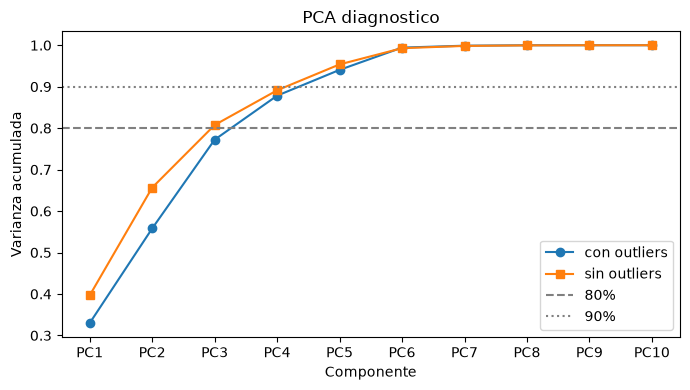

In [4]:
for pc in ["PC1", "PC2", "PC3"]:
    print(f"\nTop loadings {pc} (con):")
    display(top_loadings(load_con, pc, n=6))
    print(f"\nTop loadings {pc} (sin):")
    display(top_loadings(load_sin, pc, n=6))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(var_con["component"], var_con["cumulative_variance"], marker="o", label="con outliers")
ax.plot(var_sin["component"], var_sin["cumulative_variance"], marker="s", label="sin outliers")
ax.axhline(0.8, linestyle="--", color="gray", label="80%")
ax.axhline(0.9, linestyle=":", color="gray", label="90%")
ax.set_ylabel("Varianza acumulada")
ax.set_xlabel("Componente")
ax.set_title("PCA diagnostico")
ax.legend()
plt.tight_layout()
plt.show()


## Lectura e interpretación del diagnóstico PCA (Muestra 10,000 filas)

- **Varianza explicada y umbral 80% / 90%:** En la **Versión A (`con_outliers`)**, `PC1` explica el **`32.98%`** de la varianza (`55.80%` con `PC1+PC2`, `77.21%` con `PC1..PC3`), necesitando **`4` componentes para superar el 80%** (`87.83%`) y **`5` componentes para superar el 90%** (`94.05%`). En la **Versión B (`sin_outliers`)**, al acotar las colas de conteos con IQR, `PC1` explica el **`39.67%`** (`65.66%` con `PC1+PC2`), bastando **`3` componentes para superar el 80%** (`80.75%`) y **`5` para superar el 90%** (`95.37%`).
- **Interpretación de *loadings*:** `PC1` está dominado por el eje temporal y de duración (`dur_q_rob = +0.8325` en A y `+0.8404` en B, opuesto a `start_ord_rob = -0.3540` y `start_year_rob = -0.3502`), reflejando la dependencia lineal exacta `dur_q = end_ord - start_ord + 1`. El bloque de complejidad ocupacional (`n_skills_essential_rob` y `n_skills_competence_rob`) emerge de forma ortogonal en `PC2`/`PC3`, confirmando que la carga de competencias ESCO aporta señal independiente a la antigüedad temporal.